# Range cover: main notebook

Run from the top to the bottom in Colab with a **T4 GPU** (Runtime > Change runtime type).
All real runs happen here. The Mac only runs `--smoke` and `pytest` as fast checks.

Each step is one cell. Each script resumes, so after a disconnect, run the setup cell again and then the cell that stopped.

## Setup
From `instructions.md`. Run again after a disconnect or restart.

In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

os.environ['DATA_DIR'] = '/content/drive/MyDrive/cv_capstone_project/data'
os.environ['UV_PROJECT_ENVIRONMENT'] = '/content/.venv'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'

%cd /content/drive/MyDrive/cv_capstone_project
!pip install -q uv
!uv sync --frozen

Mounted at /content/drive
/content/drive/MyDrive/cv_capstone_project
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: /content/.venv
Prepared 103 packages in 2m 19s
Installed 103 packages in 828ms
 + annotated-doc==0.0.6
 + annotated-types==0.8.0
 + anyio==4.16.0
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.1
 + cloudpickle==3.1.2
 + contourpy==1.4.0
 + cryptography==50.0.2
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.9.0
 + cuda-toolkit==13.2.2
 + cv-capstone-project==0.1.0 (from file:///content/drive/MyDrive/cv_capstone_project)
 + cycler==0.12.1
 + earthengine-api==1.7.50
 + filelock==4.2.10
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + google-api-core==2.43.2
 + google-api-python-client==2.201.0
 + google-auth==2.62.0
 + google-auth-httplib2==0.4.4
 + google-cloud-core==2.8.0
 + google-cloud-storage==3.17.1
 + google-crc32c==1.9.0
 + google-resumable-media==2.11.0
 + googleapis-common-protos==1.76.0
 + h11==

## Check the code version
Drive must have synced the latest code from the Mac. The times must match the files on the Mac.

In [2]:
!ls -l --time-style=+%F_%T src/rangecover/*.py tests/*.py

-rw------- 1 root root  901 2026-11-16_17:07:03 src/rangecover/atomic.py
-rw------- 1 root root 8590 2026-11-16_16:55:29 src/rangecover/dinov2.py
-rw------- 1 root root 4507 2026-11-16_17:05:58 src/rangecover/evaluate.py
-rw------- 1 root root 8754 2026-11-16_17:01:42 src/rangecover/features.py
-rw------- 1 root root   71 2026-11-16_16:55:29 src/rangecover/__init__.py
-rw------- 1 root root 8395 2026-11-16_17:09:48 src/rangecover/models.py
-rw------- 1 root root 8905 2026-11-17_03:03:56 src/rangecover/results.py
-rw------- 1 root root 5871 2026-11-16_16:55:29 src/rangecover/splits.py
-rw------- 1 root root 2227 2026-11-16_16:55:29 tests/test_evaluate.py
-rw------- 1 root root 3131 2026-11-16_17:05:12 tests/test_features.py
-rw------- 1 root root 2716 2026-11-16_17:04:59 tests/test_models.py
-rw------- 1 root root 2059 2026-11-17_03:04:02 tests/test_results.py
-rw------- 1 root root 1898 2026-11-16_16:55:29 tests/test_splits.py


## Step 2a: DINOv2 features (GPU only when visits are left)
First, the script looks on Drive for visits that already have features. It copies and runs only the visits that are left (16 photos copied at the same time, with progress). When all 358 visits are done, this cell copies nothing, loads no model and takes seconds.
Output: `data/dinov2/photos/*.npy` and `data/dinov2_visit_mean.npz` (358 × 768). On a CPU-only runtime, the `nvidia-smi` line prints an error; the cell still runs.

In [3]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!uv run --frozen python -m rangecover.dinov2 --local /content/photos

name, memory.total [MiB]
Tesla T4, 15360 MiB
358/358 visits already have features; 0 to do
50/358 visits
100/358 visits
150/358 visits
200/358 visits
250/358 visits
300/358 visits
350/358 visits
358/358 visits
Saved (358, 768) to /content/drive/MyDrive/cv_capstone_project/data/dinov2_visit_mean.npz (device: cpu)


In [4]:
import numpy as np
f = np.load(os.environ['DATA_DIR'] + '/dinov2_visit_mean.npz')
print(f['features'].shape, f['features'].dtype, 'finite:', np.isfinite(f['features']).all())

(358, 768) float32 finite: True


## Step 2b: tests
Invariant 1: no site in both train and test. Invariant 2: predictions add to 100.

In [5]:
!uv run --frozen pytest -q

........................                                                 [100%]
24 passed in 26.44s


## Step 2b: the 15 test runs and the dummy model
The dummy model always predicts the mean of the training labels. Every real method must have a lower error.

In [6]:
!uv run --frozen python -m rangecover.splits
!uv run --frozen python -m rangecover.evaluate

358 visits, 336 sites, 30 blocks
run  0  seed 0  group 0  test  73 visits /  69 sites  train 285
run  1  seed 0  group 1  test  70 visits /  70 sites  train 288
run  2  seed 0  group 2  test  69 visits /  66 sites  train 289
run  3  seed 0  group 3  test  76 visits /  61 sites  train 282
run  4  seed 0  group 4  test  70 visits /  70 sites  train 288
run  5  seed 1  group 0  test  78 visits /  73 sites  train 280
run  6  seed 1  group 1  test  73 visits /  59 sites  train 285
run  7  seed 1  group 2  test  67 visits /  67 sites  train 291
run  8  seed 1  group 3  test  71 visits /  71 sites  train 287
run  9  seed 1  group 4  test  69 visits /  66 sites  train 289
run 10  seed 2  group 0  test  68 visits /  67 sites  train 290
run 11  seed 2  group 1  test  70 visits /  66 sites  train 288
run 12  seed 2  group 2  test  76 visits /  73 sites  train 282
run 13  seed 2  group 3  test  75 visits /  75 sites  train 283
run 14  seed 2  group 4  test  69 visits /  55 sites  train 289
     ma

## Step 3: features (check)
Builds the training and test feature table of each of the 15 runs and prints their sizes. Writes nothing.
Columns: 8 satellite (6 band means, NDVI, NDTI), 3 weather (rain over the last 3, 6 and 12 months) and 20 photo columns. The photo PCA is fit on the training visits of each run only. Step 4 builds the same tables again inside its loop.

In [7]:
!uv run --frozen python -m rangecover.features

358 visits; 8 satellite + 3 weather + 20 photo columns
run  0  train (285, 31)  test (73, 31)  PCA keeps 82.9% of the photo spread
run  1  train (288, 31)  test (70, 31)  PCA keeps 82.1% of the photo spread
run  2  train (289, 31)  test (69, 31)  PCA keeps 81.8% of the photo spread
run  3  train (282, 31)  test (76, 31)  PCA keeps 82.6% of the photo spread
run  4  train (288, 31)  test (70, 31)  PCA keeps 82.4% of the photo spread
run  5  train (280, 31)  test (78, 31)  PCA keeps 82.7% of the photo spread
run  6  train (285, 31)  test (73, 31)  PCA keeps 82.0% of the photo spread
run  7  train (291, 31)  test (67, 31)  PCA keeps 82.3% of the photo spread
run  8  train (287, 31)  test (71, 31)  PCA keeps 82.5% of the photo spread
run  9  train (289, 31)  test (69, 31)  PCA keeps 82.2% of the photo spread
run 10  train (290, 31)  test (68, 31)  PCA keeps 82.2% of the photo spread
run 11  train (288, 31)  test (70, 31)  PCA keeps 82.2% of the photo spread
run 12  train (282, 31)  test (76

## Step 4: the four methods on the 15 test runs
#1 RF satellite, #2 RF satellite + weather, #3 RF satellite + weather + photos, #4 linear (ridge) on all inputs. One loop; the methods differ only in model kind and input columns. CPU only, no GPU needed. It prints one line per run with the dry MAE of each method (about 1 s per run on a 10-core Mac; Colab has fewer CPUs, so the printed times show the real rate).
Output: `data/predictions.csv` (not committed) and `results/run_errors.csv` (committed). It always trains again, so a rerun checks that the numbers can be made again.

In [8]:
!uv run --frozen python -m rangecover.models

358 visits, 15 test runs, 4 methods, 500 trees per forest
run  0 done (  7.6 s)  dry MAE  m1 19.04  m2 18.94  m3 14.06  m4 13.63
run  1 done ( 12.4 s)  dry MAE  m1 11.69  m2 10.79  m3 10.76  m4  9.30
run  2 done ( 17.5 s)  dry MAE  m1 14.56  m2 14.90  m3 13.23  m4 12.30
run  3 done ( 24.8 s)  dry MAE  m1 14.53  m2 15.21  m3 13.76  m4 13.54
run  4 done ( 29.7 s)  dry MAE  m1 13.94  m2 12.85  m3 13.84  m4 12.35
run  5 done ( 35.8 s)  dry MAE  m1 16.28  m2 16.08  m3 13.95  m4 13.35
run  6 done ( 42.2 s)  dry MAE  m1 16.64  m2 15.21  m3 14.12  m4 13.00
run  7 done ( 47.0 s)  dry MAE  m1 14.12  m2 13.30  m3 13.85  m4 12.19
run  8 done ( 54.1 s)  dry MAE  m1 11.97  m2 11.41  m3 11.12  m4 11.15
run  9 done ( 59.4 s)  dry MAE  m1 17.34  m2 16.99  m3 14.26  m4 10.64
run 10 done ( 64.2 s)  dry MAE  m1 15.76  m2 14.99  m3 16.05  m4 13.94
run 11 done ( 71.8 s)  dry MAE  m1 10.66  m2 10.43  m3  9.65  m4 11.33
run 12 done ( 76.6 s)  dry MAE  m1 12.42  m2 11.86  m3 11.03  m4  9.82
run 13 done ( 81.4 

## Step 5: results table, chart and verdict
The verdict compares #3 with #2 only, with the pass mark fixed on 15 Nov. Output in `results/`: `results_table.csv`, `verdict.json`, `dry_mae_by_run.png`, `results.md`.

                                      label  mae_green  mae_dry  mae_bare  rmse_green  rmse_dry  rmse_bare
method                                                                                                    
m1                         #1 RF: satellite      12.68    15.14     10.36       17.77     19.50      13.79
m2               #2 RF: satellite + weather      12.78    14.57     10.61       17.67     18.45      14.06
m3      #3 RF: satellite + weather + photos      11.15    13.65     10.28       14.76     16.91      13.30
m4                    #4 Linear: all inputs       8.68    12.37     10.54       11.23     16.01      13.69
floor       Floor: training mean, no inputs      15.69    22.23     23.31       20.01     25.70      26.54

{
  "dry_gain": 0.9153669433504715,
  "dry_wins": 11,
  "n_runs": 15,
  "green_rise": -1.6360931090499418,
  "bare_rise": -0.3236262004218631,
  "1_dry_gain_ok": false,
  "2_dry_wins_ok": false,
  "3_green_bare_ok": true,
  "verdict": "fail",
  "m2_m

# Results

Mean over 15 site-grouped test runs, in cover points (lower is better). The pass mark uses MAE only.

| Method | MAE green | MAE dry | MAE bare | RMSE green | RMSE dry | RMSE bare |
|---|---:|---:|---:|---:|---:|---:|
| #1 RF: satellite | 12.68 | 15.14 | 10.36 | 17.77 | 19.50 | 13.79 |
| #2 RF: satellite + weather | 12.78 | 14.57 | 10.61 | 17.67 | 18.45 | 14.06 |
| #3 RF: satellite + weather + photos | 11.15 | 13.65 | 10.28 | 14.76 | 16.91 | 13.30 |
| #4 Linear: all inputs | 8.68 | 12.37 | 10.54 | 11.23 | 16.01 | 13.69 |
| Floor: training mean, no inputs | 15.69 | 22.23 | 23.31 | 20.01 | 25.70 | 26.54 |

## Verdict: method #3 against method #2

| Condition | Needed | Result | Met |
|---|---|---|---|
| 1. Dry MAE drops | ≥ 1.5 | +0.92 | no |
| 2. Runs where #3 has the lower dry MAE | ≥ 12 of 15 | 11 of 15 | no |
| 3. Green and bare MAE rise | ≤ 0.5 each | green -1.64, bare -0.32 | yes |

**Verdict: FAIL**




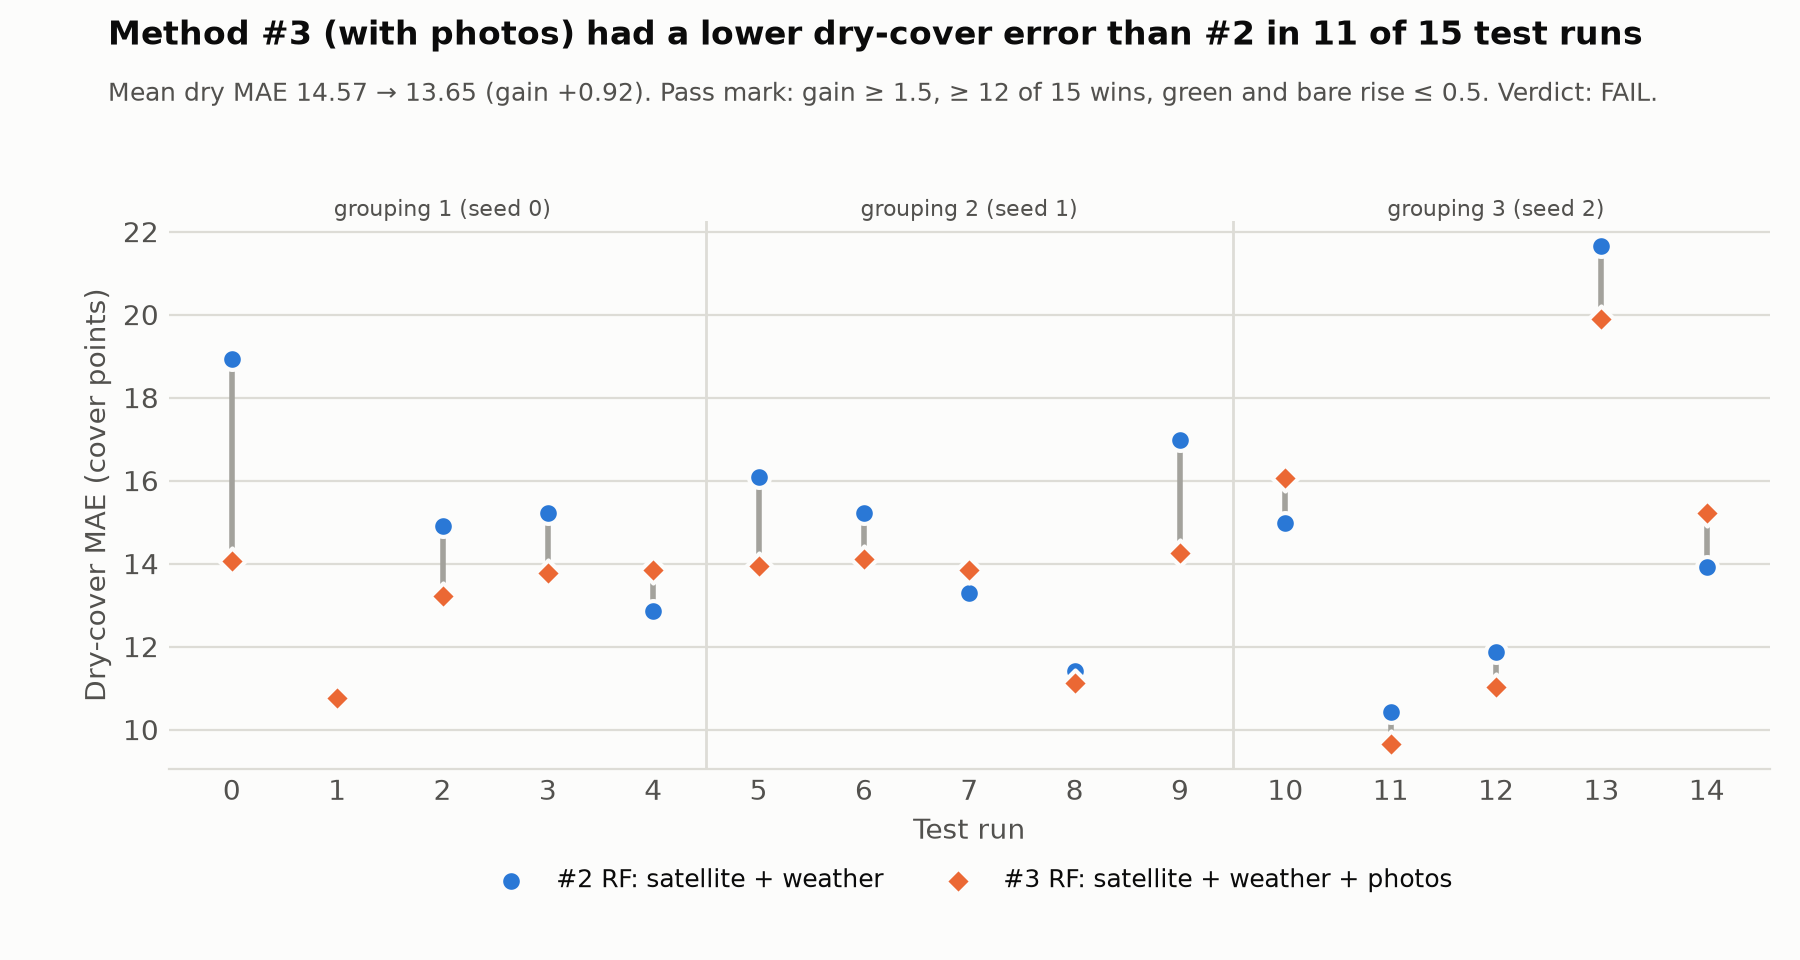

In [9]:
!uv run --frozen python -m rangecover.results

from IPython.display import Image, Markdown, display
page = open('results/results.md').read().replace('![Dry MAE per test run](dry_mae_by_run.png)', '')
display(Markdown(page))
display(Image('results/dry_mae_by_run.png', width=900))

## End
Make this the last cell, so all writes reach Drive.

In [10]:
drive.flush_and_unmount()